# Member 4 — Website, deployment and cross-domain research

**Mohamed Khaled · 16003895**  
Team: Mohamed Walid (16002100), Omar Aziz (16007095), Ahmad Salah (16008995), Mohamed Khaled (16003895).

This notebook documents Member 4’s two research questions and the website handoff. It extends the four completed Member 2/3 questions. The team total is six completed questions/charts; Member 1’s two research charts were absent from the supplied notebook and remain outstanding. The original Member 1 notebook is preserved unchanged.

At the original handoff the user instructed **no commits yet**. The website was deployed directly from local app assets. The user subsequently authorized publication of Member 4 work only; separate Member 2/3 handoffs are excluded from this repository update. AI assistance and actual contribution distinctions are retained in the contribution/prompt files.

## Data and meaning

Sources: [HPD Affordable Housing Production by Building](https://data.cityofnewyork.us/d/hg8x-zxpr), catalog H2, 9,551 original records × 41 columns; [DOT SIRTA](https://data.cityofnewyork.us/d/xeqp-qz8h), catalog T4, 13,754 original records × 23 columns. Both original datasets exceed nine columns. These are the same two full datasets selected in Member 1’s work; no additional dataset or sampling is introduced.

The separately supplied prior analysis performs source cleaning, quarantines conflicting/undated crashes, and integrates at borough/year with a secondary coverage-aware ZIP/year view. This notebook uses the compact category-aware frozen aggregate JSON generated from those cleaned records. `prepare_data.py` is the reproducible bridge, and `reports/data_provenance.json` records input hashes. Main full years: 2022–2025. ZIP research: 2023–2025, because 2022 transport ZIP completeness is only 16.26%. Partial 2026 is retained in the app, explicitly labeled, and excluded by default.

Housing year means project start, not occupancy/completion. Counted units include preservation. SIRTA means DOT-investigated serious crashes, not every NYC crash. Missing values remain unknown; these sources do not measure population or road exposure.

In [1]:
from pathlib import Path
import sys, json, inspect
import pandas as pd
from IPython.display import display, Image, Markdown, Code
ROOT=Path.cwd()
if not (ROOT/"website/data/nyc.json").exists():
    ROOT=ROOT.parent
if not (ROOT/"website/data/nyc.json").exists():
    raise RuntimeError("Run from the package root or its notebooks folder.")
sys.path.insert(0,str(ROOT/"member4"))
from research import research
main, concentration, findings=research(ROOT)
display(pd.DataFrame([findings["scope"]]))
display(Code(inspect.getsource(research),language="python"))

,main_years,main_cells,zip_years,complete_zip_years,known_units,sirta_records
0,"[2022, 2023, 2024, 2025]",20,"[2023, 2024, 2025]",306,103912,11921


def research(root=ROOT):
 root=Path(root);out=root/'member4/reports';out.mkdir(parents=True,exist_ok=True)
 d=json.loads((root/'website/data/nyc.json').read_text())
 h=pd.DataFrame(d['housing'],columns=['b','year','type','records','known_units','missing'])
 t=pd.DataFrame(d['transport'],columns=['b','year','severity','crashes','severe','fatalities'])
 h=h[h.year.isin(YEARS)].groupby(['b','year'])[['known_units','missing','records']].sum(min_count=1).reset_index()
 t=t[t.year.isin(YEARS)].groupby(['b','year'])[['crashes','severe','fatalities']].sum(min_count=1).reset_index()
 main=h.merge(t,on=['b','year'],validate='one_to_one');main['borough']=main.b.map(dict(enumerate(BOROUGHS)))
 main['housing_share_pct']=main.known_units/main.groupby('year').known_units.transform('sum')*100
 main['crash_share_pct']=main.crashes/main.groupby('year').crashes.transform('sum')*100
 main['gap_pp']=main.crash_share_pct-main.housing_share_pct
 main.to_csv(out/'M4_Q1_yearly_share_gaps.csv',index=False)
 matrix=main.pivot(index='borough',columns='year',values='gap_pp').reindex(BOROUGHS)
 plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold'})
 fig,ax=plt.subplots(figsize=(9.5,5.4));limit=float(np.abs(matrix.to_numpy()).max())
 from matplotlib.colors import LinearSegmentedColormap
 cmap=LinearSegmentedColormap.from_list('domain_gap',['#147e83','#f7f8f4','#dc795e'])
 im=ax.imshow(matrix.to_numpy(),cmap=cmap,vmin=-limit,vmax=limit,aspect='auto')
 ax.set_xticks(range(4),YEARS);ax.set_yticks(range(5),[b.title() for b in BOROUGHS]);ax.set_title('Do borough housing / serious-crash share gaps persist?',pad=18)
 for i in range(5):
  for j in range(4):ax.text(j,i,f'{matrix.iloc[i,j]:+.1f}',ha='center',va='center',color='white' if abs(matrix.iloc[i,j])>9.5 else '#142c3b',fontsize=12)
 cb=fig.colorbar(im,ax=ax,shrink=.8);cb.set_label('SIRTA share − known housing share (percentage points)')
 fig.text(.05,.02,'2022–2025 | Citywide denominators per year. Two unknown housing records excluded from known subtotals.\nCoral: larger share of SIRTA; teal: larger share of known HPD units. Descriptive distributions, not resident risk.',fontsize=9,color='#586b75')
 fig.tight_layout(rect=[0,.1,1,1]);fig.savefig(out/'M4_Q1_share_gap_heatmap.png',dpi=170,bbox_inches='tight');plt.close(fig)
 hz=pd.DataFrame(d['housingZip'],columns=['b','year','type','zip','records','known_units','missing']).groupby(['b','year','zip'])[['known_units','missing']].sum(min_count=1).reset_index()
 tz=pd.DataFrame(d['transportZip'],columns=['b','year','severity','zip','crashes','severe','fatalities']).groupby(['b','year','zip'])[['crashes']].sum(min_count=1).reset_index()
 pairs=hz.merge(tz,on=['b','year','zip'],validate='one_to_one');pairs=pairs[pairs.missing.eq(0)&pairs.known_units.notna()]
 pairs.to_csv(out/'M4_Q2_complete_matched_zip_years.csv',index=False)
 pooled=pairs.groupby(['b','zip'])[['known_units','crashes']].sum().reset_index();concentration=[]
 for b,g in pooled.groupby('b'):
  hh=float(((g.known_units/g.known_units.sum())**2).sum());th=float(((g.crashes/g.crashes.sum())**2).sum())
  concentration.append({'borough':BOROUGHS[b],'observed_zips':len(g),'housing_hhi':hh,'sirta_hhi':th,'housing_effective_zips':1/hh,'sirta_effective_zips':1/th})
 concentration=pd.DataFrame(concentration);concentration.to_csv(out/'M4_Q2_zip_concentration.csv',index=False)
 fig,ax=plt.subplots(figsize=(10,5.4));x=np.arange(5);w=.36
 for offset,col,label,color in [(-w/2,'housing_effective_zips','Housing counted units','#147e83'),(w/2,'sirta_effective_zips','SIRTA crash records','#dc795e')]:
  bars=ax.bar(x+offset,concentration[col],w,color=color,label=label);ax.bar_label(bars,fmt='%.1f',padding=3,fontsize=10)
 ax.set_xticks(x,[b.title() for b in BOROUGHS]);ax.set_ylabel('Effective ZIP count (1 / HHI)');ax.set_title('Is housing activity more concentrated within matched ZIPs?');ax.set_ylim(0,35);ax.legend(frameon=False)
 fig.tex

## M4 Q1 — Do borough-level distribution gaps persist across years?

For each borough and calendar year, compare its share of all known HPD counted units with its share of all borough-located SIRTA records. Compute **gap = SIRTA share − housing share**, in percentage points, using all five boroughs for both yearly denominators. Positive/coral values mean a larger share of SIRTA; negative/teal means a larger share of known housing units.

A heatmap reveals whether the pattern persists or reverses over time. Two housing records in the main years have unknown counted-unit values. The known-unit denominator excludes their unknown values without substituting zero or building total units. The strict aggregate is retained as unknown in the underlying analysis/app table.

,borough,year,known_units,missing,crashes,housing_share_pct,crash_share_pct,gap_pp
0,BRONX,2022,5191,0,600,31.352298,20.840570,-10.511728
1,BRONX,2023,9335,0,599,32.064713,19.867330,-12.197383
2,BRONX,2024,9800,1,622,33.833938,19.974310,-13.859628
3,BRONX,2025,8163,0,543,27.881955,18.640577,-9.241378
4,BROOKLYN,2022,6450,0,885,38.956333,30.739840,-8.216492
5,BROOKLYN,2023,10777,1,874,37.017827,28.988391,-8.029436
6,BROOKLYN,2024,8987,0,919,31.027102,29.511882,-1.515220
7,BROOKLYN,2025,8350,0,879,28.520682,30.175077,1.654395
8,MANHATTAN,2022,3163,0,570,19.103702,19.798541,0.694839
9,MANHATTAN,2023,5403,0,653,18.558719,21.658375,3.099655


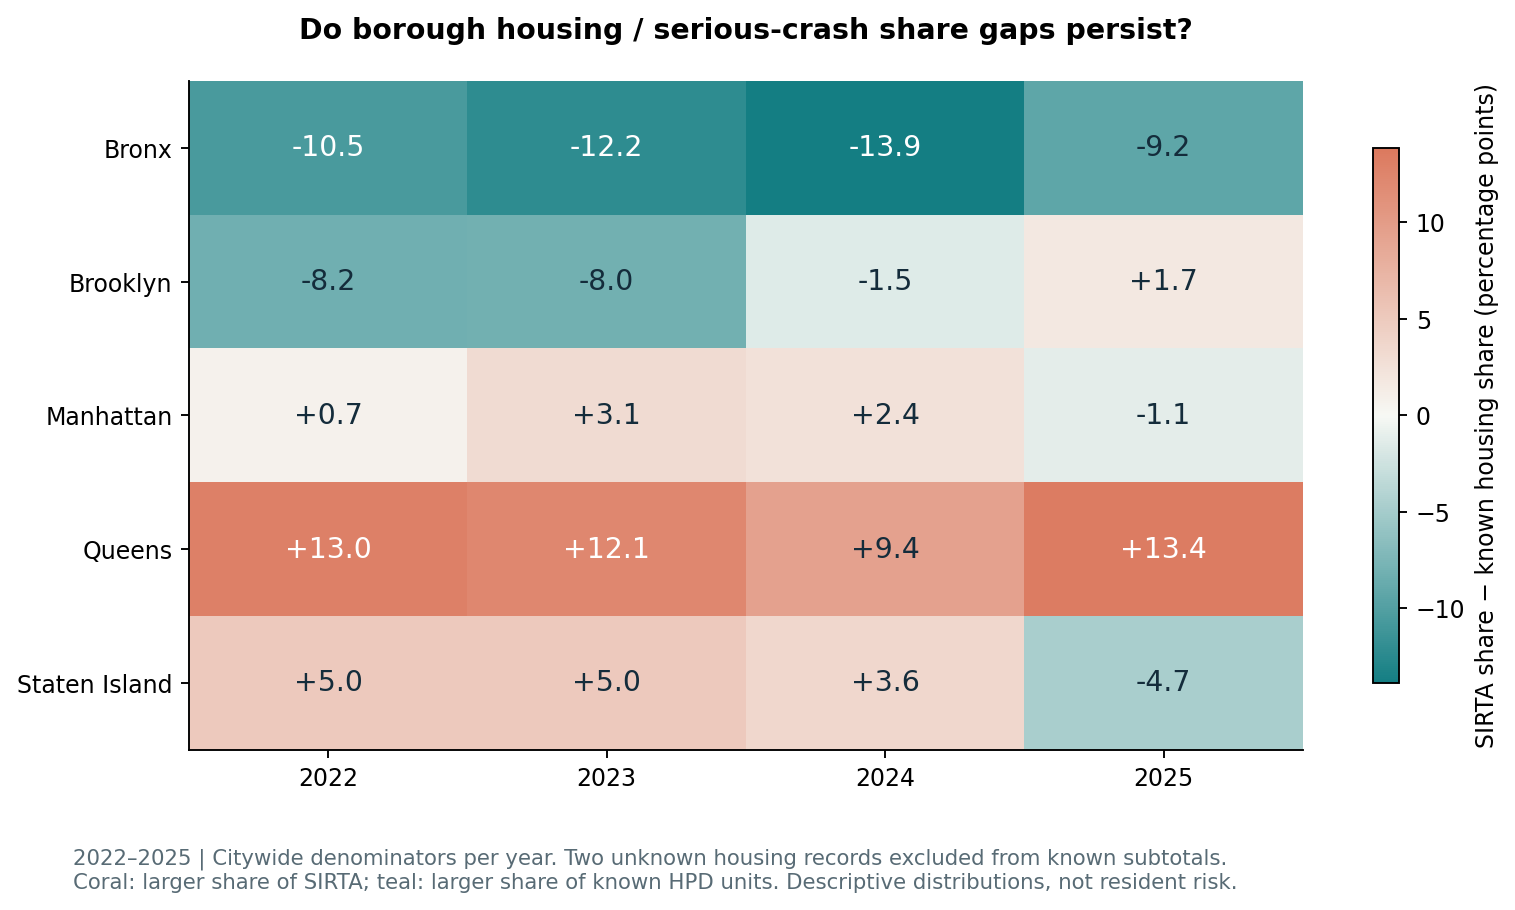

In [2]:
display(main[["borough","year","known_units","missing","crashes","housing_share_pct","crash_share_pct","gap_pp"]])
display(Image(filename=str(ROOT/"member4/reports/M4_Q1_share_gap_heatmap.png")))

**Answer:** Queens has positive gaps in every year (+12.99, +12.13, +9.40, +13.40 pp), while the Bronx has negative gaps (−10.51, −12.20, −13.86, −9.24 pp). Brooklyn changes direction by 2025. Some aggregate geographic differences are persistent, not isolated to one year.

**Limit:** different source populations, changing reporting, incomplete unit values, borough aggregation and no exposure denominator. A share gap is not a crash risk or an investment target by itself. **Use:** frame joint HPD/DOT local investigations that add population/traffic exposure and neighborhood context. No housing-to-crash causation is asserted.

## M4 Q2 — Is housing activity more concentrated across matched ZIPs?

Use only eligible matched ZIP-years in 2023–2025, excluding ambiguous borough mappings and incomplete housing counted-unit cells. Aggregate selected category rows first, one-to-one join by borough/ZIP/year, retain 306 complete cells and pool years within each ZIP. For each borough, calculate each ZIP’s share of the domain total, then **HHI = sum(share²)** and **effective ZIP count = 1/HHI**.

A grouped bar chart compares concentration on an interpretable scale: a lower effective count indicates more concentration; it can be fractional and cannot exceed the number of observed ZIPs. This compares geography within the common observed subset rather than pretending the missing ZIP records have no activity.

,borough,observed_zips,housing_hhi,sirta_hhi,housing_effective_zips,sirta_effective_zips
0,BRONX,21,0.084420,0.056159,11.845476,17.806582
1,BROOKLYN,36,0.052473,0.034928,19.057268,28.630136
2,MANHATTAN,34,0.055856,0.040296,17.903149,24.816154
3,QUEENS,33,0.091832,0.052513,10.889429,19.043012
4,STATEN ISLAND,7,0.402581,0.195480,2.483972,5.115617


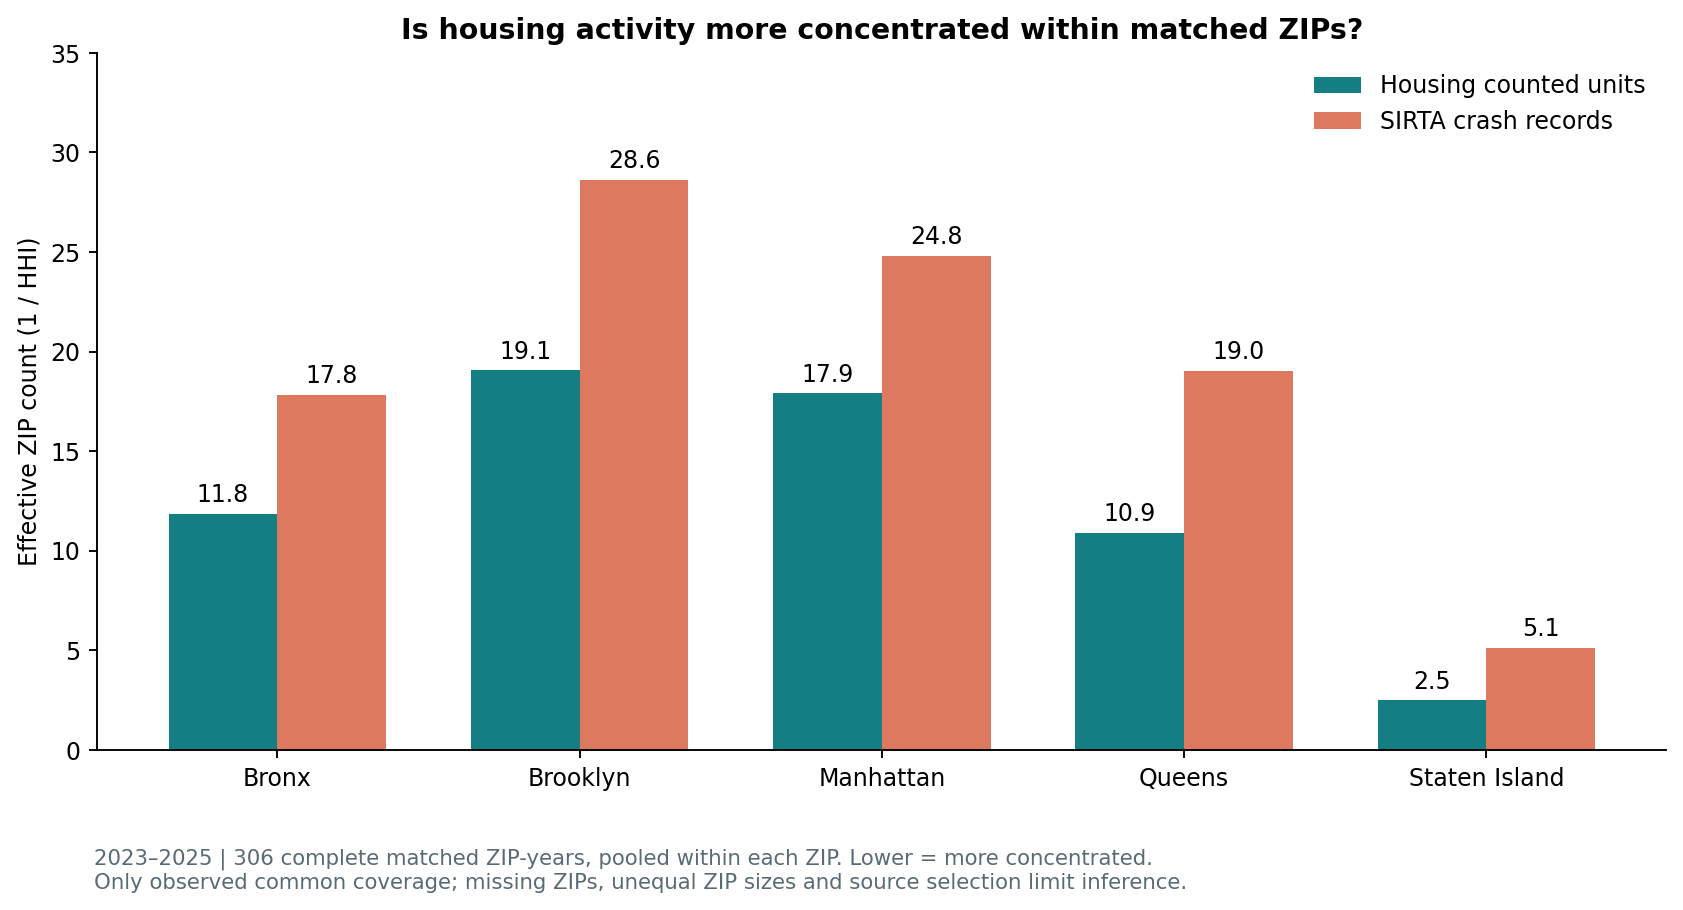

In [3]:
display(concentration)
display(Image(filename=str(ROOT/"member4/reports/M4_Q2_effective_zips.png")))
assert (concentration.housing_effective_zips <= concentration.observed_zips + 1e-9).all()
assert (concentration.sirta_effective_zips <= concentration.observed_zips + 1e-9).all()
assert (concentration.housing_effective_zips < concentration.sirta_effective_zips).all()

**Answer:** housing is more concentrated than SIRTA in all five boroughs within matched coverage. Effective housing/SIRTA ZIP counts include Queens **10.89/19.04**, Brooklyn **19.06/28.63**, and Staten Island **2.48/5.12**.

**Limit:** the selected common geography, missing ZIPs, unequal ZIP sizes and source selection can change the result. Staten Island has only seven observed ZIPs; repeated years are pooled, not treated as independent samples. No causal or significance claim follows. **Use:** the different spatial concentration patterns help agencies design local follow-up, while checking areas excluded by geography gaps.

## Website contract and behavior

The `website/` folder is a static JavaScript application with pinned Plotly charts. Four dropdowns cover borough, year, housing type and crash category. Text search parses queries such as **“Brooklyn 2022 new buildings”**, **“Queens 2023–2025 preservation fatal crashes”** and **“Bronx 2024 nonfatal”**. Unsupported years, places and conflicting categories produce a visible error and retain the last valid report.

The central **Generate Report** action rebuilds every chart, summary number, story and evidence table. Dropdown changes are pending until generation; Reset immediately restores the full-year default. Charts support hover, zoom, pan, reset and PNG export. CSV export uses the active report. The app also provides a printable report, source links, a story section, explicit limitations, mobile layout and keyboard-accessible controls.

Domain categories are filtered independently before reaggregation/join. They never imply crashes at selected housing buildings. Shares retain citywide denominators when displaying one borough. ZIP charts are restricted to selected years within 2023–2025; 2022/2026 therefore have an explicit empty secondary view. Narrow category filters can also produce no observed matched cells. Unknown data are never replaced by fabricated zero counts. Every offered dropdown combination is checked in acceptance tests.

In [4]:
import subprocess
result=subprocess.run(["node","--test","tests/acceptance.test.js","tests/core.test.js","tests/ui_contract.test.js","tests/report_session.test.js"],cwd=ROOT/"website",capture_output=True,text=True)
print(result.stdout)
print(result.stderr)
assert result.returncode==0
assert findings["scope"]["known_units"]==103912
assert findings["scope"]["sirta_records"]==11921
assert findings["scope"]["complete_zip_years"]==306
print("Independent Python research and JavaScript website acceptance checks passed.")

(node:69232) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)
✔ default website data reproduce the validated Member3 analysis (3.400417ms)
✔ every offered dropdown combination yields finite nullable measures and unique rows (40.306959ms)
(node:69233) Warning: The 'NO_COLOR' env is ignored due to the 'FORCE_COLOR' env being set.
(Use `node --trace-warnings ...` to show where the warning was created)
✔ search translates borough year housing and severity without confusing nonfatal (1.700584ms)
✔ unknown places, unsupported years and conflicting categories do not silently generate all data (2.794166ms)
✔ housing and crash categories filter independently and report keeps citywide denominators (0.825292ms)
✔ unknown unit values stay unknown and absent records stay null (0.357625ms)
✔ effective ZIP concentration uses matched cells and combines years by ZIP (0.258458ms)
(node:69234) Warning: T

## Contributions, prompts and submission status

Real team details are recorded below. The user requested the Member 2/3 work with AI assistance, so assigned responsibility does not claim independent authorship by absent members. No email is sent; the prepared submission draft must wait for review, publication of all remaining team work and the missing Member 1 research contributions. Deployment status is recorded separately in `member4/DEPLOYMENT.md`.

In [5]:
display(pd.read_csv(ROOT/"member4/CONTRIBUTIONS.csv",dtype="string"))
display(Markdown((ROOT/"member4/PROMPTS_USED.md").read_text()))

,role,name,student_id,assigned_work,status,actual_work_disclosure
0,Member 1,Mohamed Walid,16002100,Housing selection and cleaning; two research q...,Original housing notebook supplied; two resear...,Supplied original notebook retained unchanged
1,Member 2,Omar Aziz,16007095,Transportation EDA cleaning aggregation; M2 Q1/Q2,Completed in prior handoff,Prepared at Member 4 request with AI assistanc...
2,Member 3,Ahmad Salah,16008995,Integration post-cleaning assembled notebook; ...,Completed in prior handoff,Prepared at Member 4 request with AI assistanc...
3,Member 4,Mohamed Khaled,16003895,Website filters search Generate Report interac...,Website deployed; Member 4 source authorized f...,Requested and reviewed with AI assistance; Mem...


# Member 4 prompt record

User instruction:

> okay now start working on member 4's work

Existing role specification:

> Member 4: Website and deployment lead
> - Build the Dash (or other) app skeleton: layout, dropdown filters, search mode (parse text like "Brooklyn 2022 new buildings" into filters), and the central Generate Report button wired to all charts.
> - Deploy on Render or Vercel, test it, and write the README deployment section.
> - Write the final submission email.
> - 2 research questions + 2 charts.

Later user instruction:

> Member 1:Mohamed walid ID:16002100 Member 2:Omar aziz ID:16007095 Member 3: Ahmad Salah ID:16008995 Member 4: Mohamed Khaled ID:16003895 DONT DO ANY COMMITS YET

The user previously requested removal of code comments. New source follows that preference while retaining required notebook explanations and this assistance record. Codex/OpenAI assisted with data preparation, website implementation, research definitions and charts, testing, deployment documentation and the email draft. A separate read-only reviewer checked the Member 4 implementation; its task was to identify correctness/filtering/analytical errors, without edits, commits, pushes or publication. The exact user-request and role records for the prior handoffs are retained in analysis/PROMPTS_USED.md. No synthetic records or invented team approvals are used.

No submission email is sent. At the initial handoff, no Git commit or push was authorized. The later request below authorizes Member 4 publication only. Student IDs appear only in local contribution/submission materials, not in the deployed website assets.

## Subsequent publication request

> okay now i want you to commit member's 4 works since its mince using this repo link: https://github.com/Pra1m3/nyc-housing-repo-milestone1.git

This supersedes the earlier no-commits instruction for Member 4 work. The separate Member 2/3 handoffs are excluded from this publication.


## Handoff checklist

- Member 4’s two cross-domain questions, two static figures and two interactive implementations are present.
- The website integrates the four prior Member 2/3 research views, for six completed research charts in total. Member 1’s two are still needed for the required eight.
- Local setup, reproducible preparation, Vercel deployment settings, tested behavior and remaining publication steps are documented in the root README.
- Member 4 source publication is now authorized; the earlier deployment itself required no commit. The submission email is a draft only.
- Browser QA covers desktop/mobile, dropdown generation, search, invalid-search retention, reset, partial-year notice, secondary empty states and CSV export. See the verification report for completed evidence and any limitations.